# 08 · Sensitivity and robustness checks

Are the results an artefact of tuning choices? Each check changes one setting, re-runs the forecasts out of sample with the same rolling-origin design, and reports the mean pinball loss (S$, h = 2, averaged over τ) on the **validation** period 2014–19 and the **test** period 2020–26, plus the backtest cost against fixed 5% where it matters.

| Check | Settings tried | Main-run setting |
|---|---|---|
| 1. M1 look-back window | 24, 36, 48, 72, 96 rounds | 48 |
| 2. Refit frequency | M3: every 1, 2, 4, 8 rounds; M4: every 2, 4, 8 rounds | 4 |
| 3. Design of the volatility-scaled model M6 | volatility measure (6, 12, 24 rounds, EWMA) × exponent β (1, 0.5) × centred or not | EWMA, β = 1, not centred |
| 4. Adaptive calibration | step η = 0, 0.0025, 0.005, 0.01, 0.02 on M1, M3 and M6 | M7 = M1 with η chosen on 2014–19 |

M4 refit every round was left out: it takes about 7 minutes and M4 is an appendix model. M2 (SARIMAX) is left out because it is clearly the worst model in notebook 05. Run time of this notebook: about 6 minutes.

In [1]:
import sys, json, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.config import *
pd.set_option("display.width", 180); pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

In [2]:
from src.models import m1_rolling, m3_quantreg, m4_gbm, m6_volscaled, adaptive_calibration
from src.metrics import evaluate
from src.backtest import rule_buffers, block_bootstrap_diff
from src.plots import MODEL_COLORS, save
feat = pd.read_csv(PROC / "coe_features.csv")
fc = pd.read_csv(PROC / "forecasts.csv")
fc2 = fc[fc.h == H]
m0 = fc2[fc2.model == "M0"]

def summarise(f):
    """Mean pinball (S$) and mean |coverage - tau| on validation, test and 2020-22."""
    out = {}
    for label, periods in [("val 2014-19", VALID_PERIODS), ("test 2020-26", TEST_PERIODS), ("2020-22", ["2020-22"])]:
        e = evaluate(f[f.period.isin(periods)], by=("tau",))
        out[f"pinball {label}"] = e.pinball_sgd.mean()
        out[f"cov gap {label}"] = e.coverage_gap.abs().mean()
    return out

def vs_fixed5(f, rounds=None, ks=(2.3, 4)):
    """Backtest: newsvendor cost per car of this forecast's buffer minus fixed 5%, at tau* = k/(1+k)."""
    bt = rule_buffers(pd.concat([m0, f.assign(model="M1")]), H)
    if rounds is not None:
        bt = bt[bt.period.isin(rounds)]
    out = {}
    for k in ks:
        tau = min(TAUS, key=lambda x: abs(x - k / (1 + k)))
        ci = block_bootstrap_diff(bt, "R2 Rolling percentile", tau, "R1 Fixed 5%", None, k)
        out[f"k={k} vs 5% (S$)"] = ci["mean_diff"]
        out[f"k={k} CI"] = f"[{ci['ci_low']:.0f}, {ci['ci_high']:.0f}]"
    return out

## 1. M1 look-back window

M1's buffer is a percentile of the last *W* realised 2-round rises. A short window reacts fast but is noisy at τ = 0.9–0.95 (24 rounds hold only 1–2 rises above the 95th percentile); a long window is stable but slow.

In [3]:
rows = []
for w in [24, 36, 48, 72, 96]:
    f = m1_rolling(feat, H, TAUS, window=w)
    rows.append({"window": w, **summarise(f), **vs_fixed5(f), **{f"test {k}": v for k, v in vs_fixed5(f, TEST_PERIODS).items()}})
win = pd.DataFrame(rows).set_index("window")
win.to_csv(PROC / "sensitivity_window.csv")
win.round(1).assign(**{c: win[c].round(3) for c in win.columns if c.startswith("cov gap")})

,pinball val 2014-19,cov gap val 2014-19,pinball test 2020-26,cov gap test 2020-26,pinball 2020-22,cov gap 2020-22,k=2.3 vs 5% (S$),k=2.3 CI,k=4 vs 5% (S$),k=4 CI,test k=2.3 vs 5% (S$),test k=2.3 CI,test k=4 vs 5% (S$),test k=4 CI
window,,,,,,,,,,,,,,
24,"1,258.800",0.035,"2,083.400",0.013,"1,890.300",0.032,88.700,"[-18, 211]",17.100,"[-84, 108]",160.500,"[12, 351]",-57.600,"[-274, 94]"
36,"1,209.100",0.018,"1,912.600",0.007,"1,629.900",0.012,21.400,"[-65, 109]",-41.400,"[-150, 44]",62.700,"[-42, 184]",-128.000,"[-323, 18]"
48,"1,208.100",0.010,"1,916.500",0.011,"1,635.000",0.026,32.300,"[-55, 127]",-37.900,"[-156, 52]",97.200,"[-24, 244]",-127.400,"[-341, 46]"
72,"1,207.000",0.015,"1,921.800",0.017,"1,609.500",0.049,37.500,"[-42, 129]",-0.500,"[-132, 92]",100.200,"[-18, 230]",-76.200,"[-299, 108]"
96,"1,237.400",0.028,"1,941.500",0.017,"1,628.500",0.076,82.500,"[9, 164]",43.700,"[-97, 145]",147.800,"[52, 272]",-31.200,"[-249, 159]"


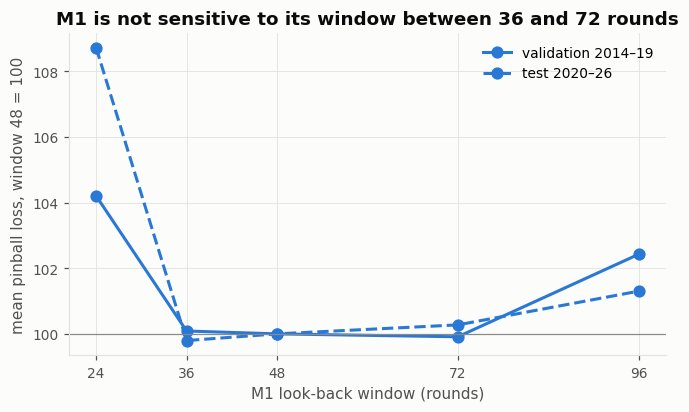

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.8))
for col, ls, lab in [("pinball val 2014-19", "-", "validation 2014–19"), ("pinball test 2020-26", "--", "test 2020–26")]:
    ax.plot(win.index, win[col] / win.loc[48, col] * 100, marker="o", ms=7, ls=ls, color=MODEL_COLORS["M1"], label=lab)
ax.axhline(100, color="#8a8984", lw=0.8)
ax.set_xticks(win.index); ax.set_xlabel("M1 look-back window (rounds)")
ax.set_ylabel("mean pinball loss, window 48 = 100"); ax.legend(loc="upper right")
ax.set_title("M1 is not sensitive to its window between 36 and 72 rounds")
save(fig, "08_sensitivity_window.png"); plt.show()

## 2. Refit frequency (M3 quantile regression, M4 gradient boosting)

The main run refits every 4 rounds (two months) and reuses the fitted model in between. Refitting every round uses every new observation as soon as it is realised.

In [5]:
rows = []
for model, fn, settings in [("M3", m3_quantreg, [1, 2, 4, 8]), ("M4", m4_gbm, [2, 4, 8])]:
    for every in settings:
        f = fc2[fc2.model == model] if every == REFIT_EVERY else fn(feat, H, TAUS, refit_every=every)
        rows.append({"model": model, "refit every": every, **summarise(f)})
        print(model, "refit every", every, "done")
refit = pd.DataFrame(rows)
refit.to_csv(PROC / "sensitivity_refit.csv", index=False)
refit.round(3)

M3 refit every 1 done


M3 refit every 2 done
M3 refit every 4 done


M3 refit every 8 done


M4 refit every 2 done
M4 refit every 4 done


M4 refit every 8 done


,model,refit every,pinball val 2014-19,cov gap val 2014-19,pinball test 2020-26,cov gap test 2020-26,pinball 2020-22,cov gap 2020-22
0,M3,1,"1,235.715",0.044,"1,938.136",0.014,"1,649.261",0.091
1,M3,2,"1,236.326",0.045,"1,934.028",0.015,"1,638.454",0.095
2,M3,4,"1,235.467",0.048,"1,926.639",0.013,"1,630.923",0.097
3,M3,8,"1,237.484",0.051,"1,914.937",0.013,"1,631.373",0.103
4,M4,2,"1,229.437",0.034,"1,917.060",0.046,"1,639.201",0.135
5,M4,4,"1,227.775",0.032,"1,907.604",0.045,"1,622.485",0.140
6,M4,8,"1,229.246",0.043,"1,904.773",0.043,"1,635.484",0.137


In [6]:
for m, g in refit.groupby("model"):
    base = g[g["refit every"] == REFIT_EVERY].iloc[0]
    for r in g.itertuples():
        print(f"{m} refit every {r[2]}: validation {r[3] / base['pinball val 2014-19'] * 100 - 100:+.1f}%, "
              f"test {r[5] / base['pinball test 2020-26'] * 100 - 100:+.1f}% vs every {REFIT_EVERY}")

M3 refit every 1: validation +0.0%, test +0.6% vs every 4
M3 refit every 2: validation +0.1%, test +0.4% vs every 4
M3 refit every 4: validation +0.0%, test +0.0% vs every 4
M3 refit every 8: validation +0.2%, test -0.6% vs every 4
M4 refit every 2: validation +0.1%, test +0.5% vs every 4
M4 refit every 4: validation +0.0%, test +0.0% vs every 4
M4 refit every 8: validation +0.1%, test -0.1% vs every 4


## 3. Design of the volatility-scaled model (M6)

Forecast = *m_t* + *s_t* × *z*_τ, with *s_t* = volatility^β and *z*_τ the τ-quantile of past standardised rises (pooled, expanding). Variants: the volatility measure, β = 1 (buffer proportional to volatility) or 0.5 (grows more slowly), and centred (*m_t* = the rolling 48-round median rise) or not (*m_t* = 0). **M6 in the main run is the variant with the lowest validation loss**; the test column is shown only to check that the choice was not lucky.

In [7]:
g = feat.sort_values(["category", "t"]).copy()
for n in [6, 24]:
    g[f"vol_{n}"] = g.groupby("category").ret_1.transform(lambda s: s.rolling(n).std())
rows = []
for vol in ["vol_6", "vol_12", "vol_24", "vol_ewma"]:
    for beta in [1.0, 0.5]:
        for centre in [False, True]:
            f = m6_volscaled(g, H, TAUS, vol=vol, beta=beta, centre=centre)
            rows.append({"volatility": vol, "beta": beta, "centred": centre, **summarise(f)})
vs = pd.DataFrame(rows).sort_values("pinball val 2014-19")
vs["rank val"] = range(1, len(vs) + 1)
vs["rank test"] = vs["pinball test 2020-26"].rank().astype(int)
vs.to_csv(PROC / "sensitivity_volscaled.csv", index=False)
m1_ref = summarise(fc2[fc2.model == "M1"])
print(f"M1 for reference: validation {m1_ref['pinball val 2014-19']:,.0f}, test {m1_ref['pinball test 2020-26']:,.0f}")
vs.round(3)

M1 for reference: validation 1,208, test 1,917


,volatility,beta,centred,pinball val 2014-19,cov gap val 2014-19,pinball test 2020-26,cov gap test 2020-26,pinball 2020-22,cov gap 2020-22,rank val,rank test
12,vol_ewma,1.000,False,"1,188.344",0.035,"1,928.668",0.047,"1,611.844",0.088,1,3
8,vol_24,1.000,False,"1,190.795",0.033,"1,948.311",0.054,"1,610.482",0.096,2,5
15,vol_ewma,0.500,True,"1,193.793",0.027,"1,965.668",0.011,"1,644.015",0.060,3,7
11,vol_24,0.500,True,"1,195.761",0.027,"1,965.807",0.012,"1,636.633",0.059,4,8
10,vol_24,0.500,False,"1,197.990",0.043,"1,912.779",0.043,"1,595.182",0.088,5,2
13,vol_ewma,1.000,True,"1,198.045",0.036,"1,973.581",0.009,"1,644.531",0.056,6,9
7,vol_12,0.500,True,"1,203.461",0.024,"1,983.962",0.011,"1,626.878",0.059,7,10
9,vol_24,1.000,True,"1,204.187",0.034,"1,984.551",0.010,"1,632.948",0.058,8,11
14,vol_ewma,0.500,False,"1,204.219",0.050,"1,906.657",0.041,"1,593.302",0.082,9,1
3,vol_6,0.500,True,"1,208.221",0.023,"2,001.868",0.011,"1,676.161",0.060,10,12


In [8]:
top = vs.iloc[0]
print(f"Validation winner: {top.volatility}, beta = {top.beta}, centred = {top.centred} "
      f"(validation {top['pinball val 2014-19']:,.0f}, test {top['pinball test 2020-26']:,.0f}, test rank {top['rank test']} of {len(vs)})")
print("Spearman rank correlation of the 16 variants, validation vs test:",
      round(vs[["pinball val 2014-19", "pinball test 2020-26"]].corr(method="spearman").iloc[0, 1], 2))
print(f"Variants beating M1 on validation: {(vs['pinball val 2014-19'] < m1_ref['pinball val 2014-19']).sum()} of {len(vs)}; "
      f"on test: {(vs['pinball test 2020-26'] < m1_ref['pinball test 2020-26']).sum()} of {len(vs)}")

Validation winner: vol_ewma, beta = 1.0, centred = False (validation 1,188, test 1,929, test rank 3 of 16)
Spearman rank correlation of the 16 variants, validation vs test: 0.61
Variants beating M1 on validation: 9 of 16; on test: 2 of 16


## 4. Adaptive calibration: better coverage, but cheaper buffers?

Online quantile tracking shifts each model's quantile by θ_t, nudged after every resolved forecast (delayed by h rounds). Larger η reacts faster. η = 0 is the base model.

In [9]:
rows = []
bases = {"M1": fc2[fc2.model == "M1"], "M3": fc2[fc2.model == "M3"], "M6": fc2[fc2.model == "M6"]}
for m, f in bases.items():
    for eta in [0, 0.0025, 0.005, 0.01, 0.02]:
        rows.append({"model": m, "eta": eta, **summarise(adaptive_calibration(f, eta))})
cal = pd.DataFrame(rows)
cal.to_csv(PROC / "sensitivity_calibration.csv", index=False)
cal.round(3)

,model,eta,pinball val 2014-19,cov gap val 2014-19,pinball test 2020-26,cov gap test 2020-26,pinball 2020-22,cov gap 2020-22
0,M1,0.000,"1,208.090",0.010,"1,916.524",0.011,"1,635.002",0.026
1,M1,0.002,"1,218.368",0.017,"1,951.372",0.019,"1,665.755",0.004
2,M1,0.005,"1,227.501",0.021,"1,983.915",0.023,"1,697.550",0.020
3,M1,0.010,"1,248.824",0.017,"2,026.581",0.020,"1,730.303",0.036
4,M1,0.020,"1,298.455",0.014,"2,120.792",0.017,"1,779.983",0.040
5,M3,0.000,"1,235.467",0.048,"1,926.639",0.013,"1,630.923",0.097
6,M3,0.002,"1,232.716",0.019,"1,952.964",0.010,"1,646.880",0.089
7,M3,0.005,"1,238.890",0.006,"1,968.771",0.010,"1,641.271",0.054
8,M3,0.010,"1,258.640",0.006,"2,006.118",0.012,"1,665.099",0.016
9,M3,0.020,"1,306.339",0.006,"2,072.244",0.012,"1,697.871",0.015


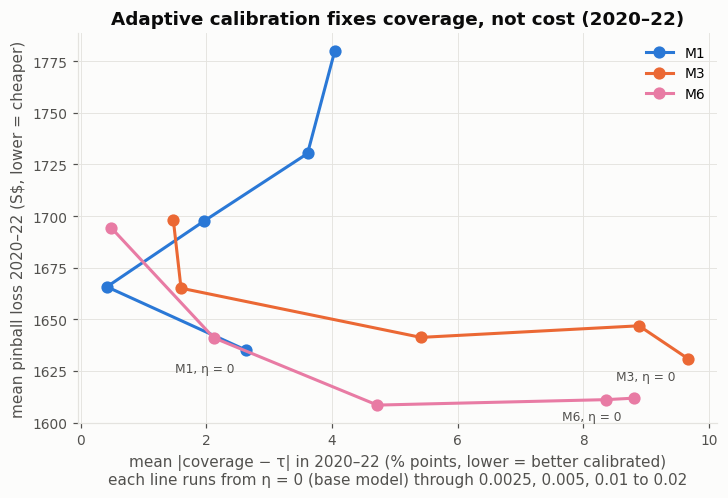

In [10]:
fig, ax = plt.subplots(figsize=(7.5, 4.6))
for m, g in cal.groupby("model"):
    ax.plot(g["cov gap 2020-22"] * 100, g["pinball 2020-22"], marker="o", ms=7, color=MODEL_COLORS[m], label=m)
    r = g.iloc[0]
    ax.annotate(f"{m}, η = 0", (r["cov gap 2020-22"] * 100, r["pinball 2020-22"]), textcoords="offset points", xytext=(-8, -14), fontsize=8, color="#52514e", ha="right")
ax.set_xlabel("mean |coverage − τ| in 2020–22 (% points, lower = better calibrated)\neach line runs from η = 0 (base model) through 0.0025, 0.005, 0.01 to 0.02")
ax.set_ylabel("mean pinball loss 2020–22 (S$, lower = cheaper)")
ax.set_title("Adaptive calibration fixes coverage, not cost (2020–22)"); ax.legend(loc="upper right")
save(fig, "08_calibration_tradeoff.png"); plt.show()

In [11]:
for m, g in cal.groupby("model"):
    b = g[g.eta == 0].iloc[0]
    best_cov = g.loc[g["cov gap 2020-22"].idxmin()]
    print(f"{m}: 2020-22 coverage gap {b['cov gap 2020-22']:.3f} -> {best_cov['cov gap 2020-22']:.3f} at eta = {best_cov.eta}, "
          f"while the 2020-22 pinball goes {b['pinball 2020-22']:,.0f} -> {best_cov['pinball 2020-22']:,.0f} "
          f"and the test pinball {b['pinball test 2020-26']:,.0f} -> {best_cov['pinball test 2020-26']:,.0f}")

M1: 2020-22 coverage gap 0.026 -> 0.004 at eta = 0.0025, while the 2020-22 pinball goes 1,635 -> 1,666 and the test pinball 1,917 -> 1,951
M3: 2020-22 coverage gap 0.097 -> 0.015 at eta = 0.02, while the 2020-22 pinball goes 1,631 -> 1,698 and the test pinball 1,927 -> 2,072
M6: 2020-22 coverage gap 0.088 -> 0.005 at eta = 0.02, while the 2020-22 pinball goes 1,612 -> 1,694 and the test pinball 1,929 -> 2,086


## Summary

The cells above give the numbers; the reading is in the written report (robustness section). In short: the conclusions of notebooks 05–07 do not depend on the window, the refit frequency, or the M6 design, and the choice of M6's design on the validation period does not carry over reliably to the test period.